In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from scipy import stats
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

np.set_printoptions(legacy='1.25') #removes the funny printing

# p-hacking HW
### Homeworks are now for 2 classes.  They will take twice as long and count twice as much.  Same rules apply. 

- In a markdown cell write down the AI model you use if needed
- This Homework is following the notes.  Use the notes!!!!
- You will see each question and my answers below.  Your HW should look very similar but with code and some more epxlanation. 
- If you get stuck try the notes.  Try and find the cell in the notes where we did something similar.
- If you are truly stuck then come to office hours, talk to a friend, use google or AI for help.  If you use help on a question write down what you asked and what you learned
- I am not sure how long this HW will take.

#### AI Model:

# Overview

- I did field work in Bangladesh with a colleague from Britain (Edwin Gnanaprakasam).  Edwin then went and did illumina sequencing to look at microbial species diversity in Bangladesh sediment.  He did 16s rRNA analysis of the DNA and found percent species abundance.  I then did analysis of the water and sediment to get the arsenic content.   Edwin wanted to know what bacterial species from this large dataset he should further investigate.  Now we want to look at bacterical species and see if there are correlations with the the different arsenic species.  He is asking if you can give him a nice notebook and figure.  Here is a [link](https://journals.asm.org/doi/10.1128/mbio.01326-17?url_ver=Z39.88-2003&rfr_id=ori%3Arid%3Acrossref.org&rfr_dat=cr_pub++0pubmed) to the paper we published.  

- Your mission if you choose..........  Is to p-hack this data.  We are going to split of the class to look at different sites and different data.  

- If you do this homework and structure it well you should have a notebook that can work for almost any data file in the future when examining correlations


# Q1
- Read in the Fall2026ClassList.xlsx with sheet 'class list' and set the index_col to uni.
- You will need the updated file. 
- Your uni should be in the class list.
- Use your pandas nomenclature to show the values associated with your uni.
- This will give you the data you need to analyze on this and future homeworks.
- You can look in the excel file to see how this is set up.  But you need to do the pandas call to see it also.  


In [62]:
dfName=pd.read_excel('../Fall2026ClassList.xlsx',sheet_name='class list',index_col='uni')
dfName.loc['bjm2103']

Name              Mailloux, Brian
WellData                    Drink
SiteName                    SiteB
ArsenicSpecies              As2S3
NYCTree                    status
Core#                   18UWHC004
Poster Group                    4
Name: bjm2103, dtype: object

# Q2 - All correlations in a PDF file
- read in the Species-Arsenic-Data-Cleaned.xlsx file.
- read in the sheet from your site
- use the arsenic species from Class list to correlate to the bacterial speices
- drop the other columns from the names of columns you don't want to correlate to
- You just want to look at bacterial species.
- Make a pdf file that contains a plot of As versus every other parameter.
- Make sure it is labeled nicely and in one pdf file.
- Arsenic species should be on the x-axis and the other parameters should be on the y-axis.
- each figure needs a best fit line and the results
- Each parameter should be on one page.
- make sure your axes go in the correct direction.  We are not plotting depth anymore
- your graphs should be square.
- Choose a color and symbol you like for your plots
- You will need to hand in your pdf file of results.
- your plot will not show up in the notebook.
- you need to save all your results data to a new dataframe


In [63]:
site='SiteB'
Xcolumn='As3'
pdf_path = f'Results/{site}_{Xcolumn}.pdf' #Name a pdf file
excel_path = f'Results/{site}_{Xcolumn}.xlsx' #Name a pdf file


df=pd.read_excel('Species-Arsenic-Data-Cleaned.xlsx',sheet_name='SiteB')

columns_to_plot = df.drop(columns=['As5','As3','As2S3','Well','Depth (m)']).columns
results_list = [] # List to collect regression results


# Text box properties
props=dict(boxstyle ='roundtooth,pad=0.5'
          ,facecolor ='coral'
          ,edgecolor ='purple'
          ,alpha =0.5
          ,hatch ='/')  #properties of the text box

with PdfPages(pdf_path) as pdf:
    for Ycolumn in columns_to_plot :

        dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row
        
        # turn on plot
        fig,ax=plt.subplots(layout='tight',figsize=(5,5))
        
        # Scatter plot
        ax.scatter(dfClean[Xcolumn]
                   ,dfClean[Ycolumn]
                   ,alpha=0.5
                   ,color='xkcd:red'
                  ,marker=r'$\heartsuit$'
                  ,label='Data')
        
        # Regression
        LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
        textstr= (
            f'm={LinResult.slope:.3f}\n'
            f'b={LinResult.intercept:.3f}\n'
            f'$r^2$={LinResult.rvalue**2:.3f}\n'
            f'p={LinResult.pvalue:.3f}'
        )
        results_list.append({
            'Xcolumn': Xcolumn,
            'Ycolumn': Ycolumn,
            'r2': LinResult.rvalue**2,
            'rvalue': LinResult.rvalue,
            'pvalue': LinResult.pvalue,
            'slope': LinResult.slope,
            'intercept': LinResult.intercept,
            'stderr': LinResult.stderr,
            'n_samples': len(dfClean),
        })
        
        ## Best fit line
        x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
        y_fit = x_fit*LinResult.slope + LinResult.intercept
        
        ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')
        
        # Label Plot
        ax.set_xlabel(Xcolumn,fontsize=14)
        ax.set_ylabel(Ycolumn,fontsize=14)
        
        ax.text(0.95,0.95, textstr, transform=ax.transAxes
                ,fontsize=10 ,va='top', ha='right', bbox=props)     #add the text box

        # Save and close
        pdf.savefig(dpi=200,bbox_inches='tight')  # save to a file        
        plt.close(fig) #closes the fig each time through to save space. 

df_r2 = (
    pd.DataFrame(results_list)
    .sort_values(by='r2', ascending=False)
)
df_r2.to_excel(excel_path,index=False)

print(f'Successfully exported {len(columns_to_plot)} pages to {pdf_path}!')
print(f'Successfully exported {len(df_r2)} data to {excel_path}!')


Successfully exported 561 pages to Results/SiteB_As3.pdf!
Successfully exported 561 data to Results/SiteB_As3.xlsx!


# Q2 Subplots of top fits!
- Make a plot with subplots that is your As sepecies versus the 6 bacterial species with the best fits
- Save this graph to a jpeg and turn that in .
- Make sure your graphs look good and have the best fit data
- They should have letters denoting them like in the packet
- In a markdwon cell note how many figures are statisitcall significant at what level.  you might need to look in your pdf file.
- Make a nice table in markdown.

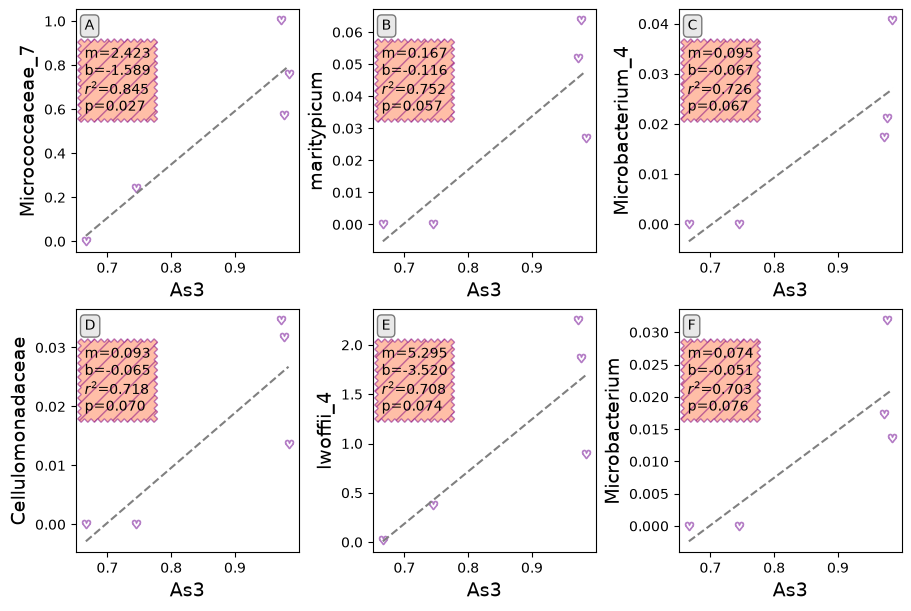

In [67]:
nrows=2
ncols=3

filename=f'Results/{site}_{Xcolumn}_{nrows}_by_{ncols}.jpg'

# 2. Text box properties
props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='//')  #properties of the text box

props2=dict(boxstyle='round',facecolor='lightgrey',alpha=0.5)  #for the letters

fig,ax2d=plt.subplots(nrows,ncols,layout='constrained',figsize=(9,6))

for count, ax in enumerate(ax2d.flat):

    # Set and clean data
    Ycolumn=df_r2.iloc[count]["Ycolumn"]
    dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row
    
    # Scatter plot
    ax.scatter(dfClean[Xcolumn]
               ,dfClean[Ycolumn]
               ,alpha=0.5
               ,color='xkcd:purple'
              ,marker=r'$\heartsuit$'
              ,label='Data')
    
    # Regression
    LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
    textstr= (
        f'm={LinResult.slope:.3f}\n'
        f'b={LinResult.intercept:.3f}\n'
        f'$r^2$={LinResult.rvalue**2:.3f}\n'
        f'p={LinResult.pvalue:.3f}'
    )
    
    ## Best fit line
    x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
    y_fit = x_fit*LinResult.slope + LinResult.intercept
    
    ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')
    
    # Label Plot
    ax.set_xlabel(Xcolumn,fontsize=14)
    ax.set_ylabel(Ycolumn,fontsize=14)
    ax.text(0.04,0.85, textstr, transform=ax.transAxes
            ,fontsize=10 ,va='top',ha='left' ,bbox=props)     #add the text box
    ax.text(0.04,0.96,chr(count + ord('A'))
            ,transform=ax.transAxes,fontsize=10,va='top',ha='left'
            ,bbox=props2)                                      ## the letters

fig.savefig(filename,dpi=200,bbox_inches='tight')
plt.show()

#### How Many species are signicant?  
- The table shows the number of species significant at each level.  

| Significance Level | Number of Species |
| -------- | -------- |
| p<0.05  | ????  |
| p<0.01  | %%%%  |
| p<0.001  | **** |
| Sum |   #####|


# Q3
- Make a Seaborn Heatmap to see if the top 20 species that are correlated with arsenic
- This is a three part question
- Part1: show your df_r2 dataframe
- Part2: show the top 20 species
- Part3: make the heatmap
- Part4: Comment in 1 or 2 sentences what the results mean for the correlations with arsenic and the other microbial species. 

### Q3-1

In [47]:
df_r2['Ycolumn']

,Xcolumn,Ycolumn,r2,rvalue,pvalue,slope,intercept,stderr,n_samples
176,As2S3,Syntrophobacteraceae_2,0.998701,0.999350,0.000020,0.262488,-0.000701,0.005466,5
438,As2S3,BSV26,0.986690,0.993323,0.000654,0.388789,-0.003366,0.026071,5
543,As2S3,Sphingomonadaceae_6,0.986690,0.993323,0.000654,0.194395,-0.001683,0.013035,5
151,As2S3,Aurantimonadaceae,0.982470,0.991196,0.000990,0.502491,0.003866,0.038752,5
346,As2S3,Ellin6067,0.972892,0.986353,0.001910,0.434397,0.002884,0.041864,5
...,...,...,...,...,...,...,...,...,...
46,As2S3,Acinetobacter,0.000037,-0.006046,0.992301,-0.010687,0.263060,1.020449,5
266,As2S3,Sphingomonas_3,0.000014,0.003718,0.995266,0.000636,0.016787,0.098750,5
36,As2S3,Arthrobacter,NaN,NaN,NaN,0.000000,0.000000,NaN,5
313,As2S3,Spirosoma,NaN,NaN,NaN,0.000000,0.000000,NaN,5


### Q3-2

In [56]:
df_r2['Ycolumn'][0:20].values

<StringArray>
[   'Micrococcaceae_7',         'maritypicum',    'Microbacterium_4',
   'Cellulomonadaceae',           'lwoffii_4',      'Microbacterium',
           'lwoffii_2',       'Terracoccus_2',   'Micrococcaceae_15',
   'Micrococcaceae_19',     'Acinetobacter_7',   'Exiguobacterium_4',
   'Exiguobacterium_3',     'Acinetobacter_6',             'lwoffii',
            'pulmonis',    'Micrococcaceae_3',  'Oxalobacteraceae_9',
 'Oxalobacteraceae_19',    'Microbacterium_3']
Length: 20, dtype: str

### Q3-3

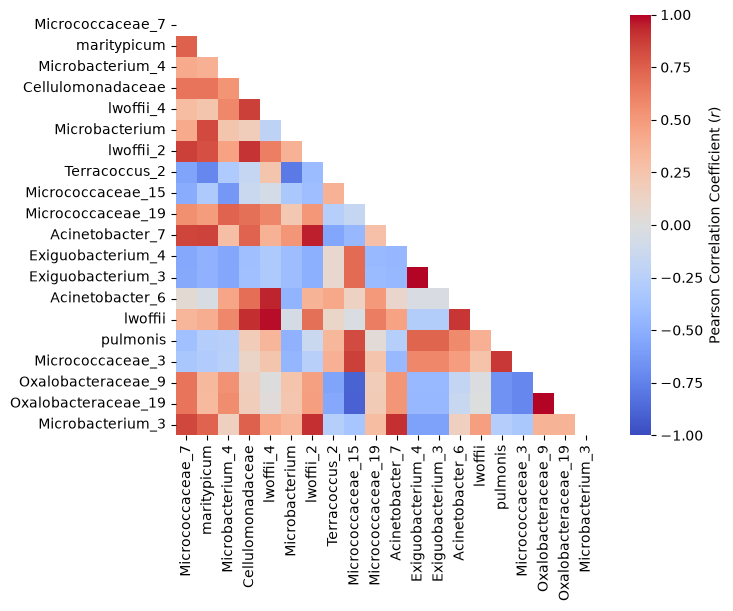

In [58]:
columns_to_plot = df_r2['Ycolumn'][0:20].values # df.drop(columns=['As5','As3','As2S3','Well','Depth (m)']).columns

# Calculate pairwise Pearson r values
corr_matrix = df[columns_to_plot].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

# Draw the heatmap
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',  # Diverging colormap (-1 blue, 0 white, +1 red)
    vmax=1.0,
    vmin=-1.0,
    mask=mask,
    annot=False,  # Hide numbers inside cells
    linewidths=0,  # Remove grid lines between cells
    cbar=True,  # Keep colorbar scale (set to False to hide as well)
    square=True,  # Keep cells perfectly square
    cbar_kws={'label': "Pearson Correlation Coefficient ($r$)"},
    ax=ax,
)

#Save and display
fig.savefig('Results/Correlation_Matrix.jpg', dpi=200, bbox_inches='tight')
plt.show()

### Q3-4
The results indicate........

<div style="page-break-before: always;"></div>
### New Page.  Grays out the cells.  Make sure to press save after graying.  Prints the pdf.  Erases the last page.  Make sure to go back and do edit->Clear Cell Output to remove the gray

In [69]:
%%html
<style>
@media print {
    body {
        zoom: 0.80; /* Scales everything down to 80% of original size */
    }
}
</style>

In [ ]:
from IPython.display import HTML

HTML("""
<style>
/* 1. Hide CODE inputs only (specifically targeting input editors, NOT output text) */
.jp-CodeCell .jp-InputArea-editor,
.jp-CodeCell .jp-InputPrompt,
.jp-CodeCell .cm-editor,
.jp-InputArea pre,
div.code_cell div.input_area,
div.code_cell div.prompt {
    display: none !important;
}

/* 2. Render the code input box as a solid gray placeholder */
.jp-CodeCell .jp-Cell-inputWrapper,
div.code_cell div.input {
    background-color: #cccccc !important;
    border: 1px solid #999999 !important;
    border-radius: 4px !important;
    min-height: 28px !important;
    margin-bottom: 8px !important;
}

/* 3. Force printed text and standard output to remain 100% sharp and black */
.jp-OutputArea pre,
div.output_subarea pre,
div.output_text pre {
    display: block !important;
    opacity: 1.0 !important;
    color: #000000 !important;
    filter: none !important;
    background-color: transparent !important;
}

/* 4. Keep plots, images, and Markdown text fully visible */
.jp-MarkdownCell, div.text_cell { opacity: 1.0 !important; }
.jp-Cell-outputWrapper, .jp-OutputArea { opacity: 1.0 !important; }
</style>
""")

In [71]:
import ipynbname
from pypdf import PdfReader, PdfWriter

# Dynamically fetch the current notebook's name (without the .ipynb extension)
filename = ipynbname.name()

# Convert to PDF
!uv run jupyter nbconvert --to webpdf {filename}.ipynb

# Strip the last page
reader = PdfReader(f"{filename}.pdf")
writer = PdfWriter()
for page in reader.pages[:-1]:
    writer.add_page(page)
writer.write(f"{filename}.pdf")

[NbConvertApp] Converting notebook p-hacking_hw.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Building PDF
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 399301 bytes to p-hacking_hw.pdf


(True, <_io.FileIO [closed]>)